In [1]:
# Fraud Detection Pipeline
# Supervised Learning Project
# Project 2 - DecodeLabs

print("Fraud Detection Pipeline")
print("Project 2 - Supervised Learning")

Fraud Detection Pipeline
Project 2 - Supervised Learning


In [2]:

import pandas as pd
import os

print("Files uploaded:")
print(os.listdir('/content'))


Files uploaded:
['.config', 'creditcard.csv', 'archive.zip', 'sample_data']


In [3]:

import pandas as pd
import os

# Find the CSV file
csv_files = [f for f in os.listdir('/content') if f.endswith('.csv')]
print("CSV files found:", csv_files)

# Load the dataset
df = pd.read_csv('/content/' + csv_files[0])

# Display the first 5 rows
print("\nFirst 5 rows:")
display(df.head())

# Display dataset size
print("\nDataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())


CSV files found: ['creditcard.csv']

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0



Dataset shape: (49610, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [4]:

# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Count legitimate and fraudulent transactions
print("\nTransaction class distribution:")
print(df['Class'].value_counts())

# Calculate percentage of each class
print("\nPercentage distribution:")
print((df['Class'].value_counts(normalize=True) * 100).round(2))


Missing values in each column:
27

Duplicate rows: 218

Transaction class distribution:
Class
0.0    49461
1.0      148
Name: count, dtype: int64

Percentage distribution:
Class
0.0    99.7
1.0     0.3
Name: proportion, dtype: float64


In [5]:

# 1. Find columns with missing values
print("Missing values by column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 2. Check duplicate rows in detail
print("\nTotal duplicate rows:", df.duplicated().sum())

print("\nSample duplicate rows:")
display(df[df.duplicated(keep=False)].head(10))

# 3. Check the data types
print("\nColumn data types:")
print(df.dtypes)

# 4. Check whether the target column has missing values
print("\nMissing Class values:", df['Class'].isnull().sum())


Missing values by column:
V4        1
V5        1
V6        1
V7        1
V8        1
V9        1
V10       1
V11       1
V12       1
V13       1
V14       1
V15       1
V16       1
V17       1
V18       1
V19       1
V20       1
V21       1
V22       1
V23       1
V24       1
V25       1
V26       1
V27       1
V28       1
Amount    1
Class     1
dtype: int64

Total duplicate rows: 218

Sample duplicate rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0.0
33,26,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0.0
34,26,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0.0
35,26,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0.0
112,74,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0.0
113,74,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0.0
114,74,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0.0
115,74,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0.0
220,145,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0.0
221,145,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0.0



Column data types:
Time        int64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class     float64
dtype: object

Missing Class values: 1


In [6]:

# Keep a copy of the original dataset
df_original = df.copy()

print("Rows before cleaning:", len(df))

# Remove rows containing missing values
df = df.dropna().copy()

print("Rows after removing missing values:", len(df))

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df))

# Check whether cleaning was successful
print("\nMissing values remaining:", df.isnull().sum().sum())
print("Duplicate rows remaining:", df.duplicated().sum())

# Check fraud and legitimate transactions again
print("\nTransaction distribution after cleaning:")
print(df['Class'].value_counts())


Rows before cleaning: 49610
Rows after removing missing values: 49609
Rows after removing duplicates: 49391

Missing values remaining: 0
Duplicate rows remaining: 0

Transaction distribution after cleaning:
Class
0.0    49243
1.0      148
Name: count, dtype: int64


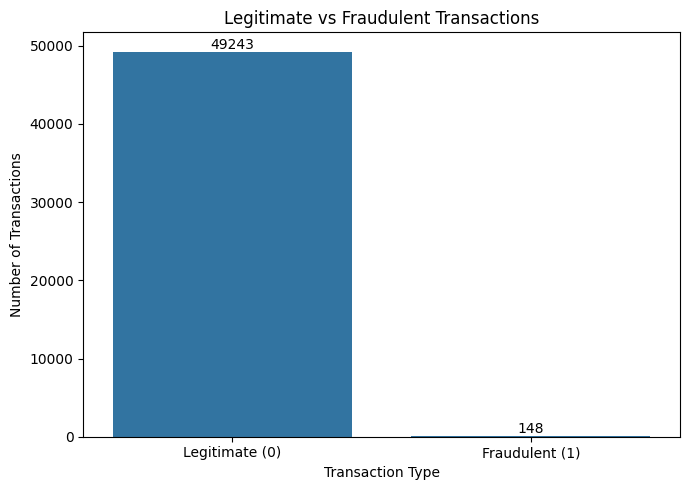

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count legitimate and fraudulent transactions
class_counts = df['Class'].value_counts().sort_index()

# Create a bar chart
plt.figure(figsize=(7, 5))
sns.barplot(
    x=['Legitimate (0)', 'Fraudulent (1)'],
    y=class_counts.values
)

plt.title('Legitimate vs Fraudulent Transactions')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')

# Display values on top of the bars
for i, value in enumerate(class_counts.values):
    plt.text(i, value + 300, str(value), ha='center')

plt.tight_layout()
plt.show()


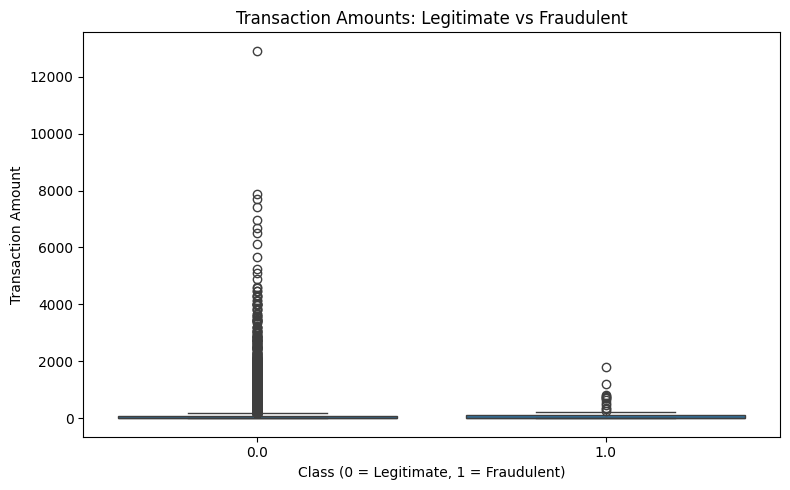

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Class',
    y='Amount'
)

plt.title('Transaction Amounts: Legitimate vs Fraudulent')
plt.xlabel('Class (0 = Legitimate, 1 = Fraudulent)')
plt.ylabel('Transaction Amount')
plt.tight_layout()
plt.show()


In [9]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop('Class', axis=1)
y = df['Class'].astype(int)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the results
print("Total dataset:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nFraud cases in training data:", y_train.sum())
print("Fraud cases in testing data:", y_test.sum())


Total dataset: (49391, 30)
Training features: (39512, 30)
Testing features: (9879, 30)

Fraud cases in training data: 118
Fraud cases in testing data: 30


In [10]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create a machine learning pipeline
model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


Model Evaluation Results
-------------------------
Accuracy: 0.9858
Precision: 0.1687
Recall: 0.9333
F1-Score: 0.2857

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      0.99      9849
  Fraudulent       0.17      0.93      0.29        30

    accuracy                           0.99      9879
   macro avg       0.58      0.96      0.64      9879
weighted avg       1.00      0.99      0.99      9879



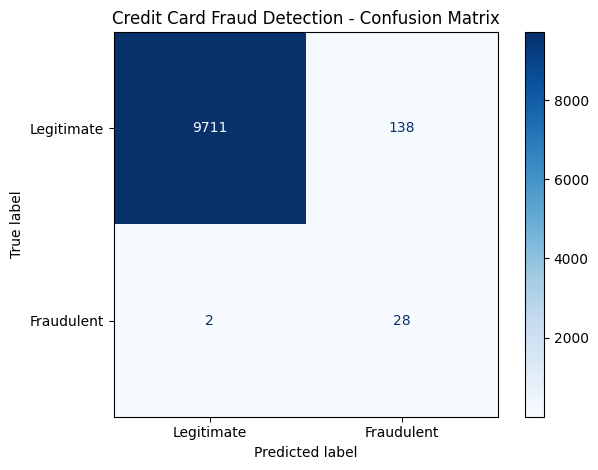

In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on unseen test data
y_pred = model.predict(X_test)

# Calculate performance metrics
print("Model Evaluation Results")
print("-------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

# Detailed report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Legitimate', 'Fraudulent'],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Fraudulent']
)

display.plot(cmap='Blues', values_format='d')
plt.title('Credit Card Fraud Detection - Confusion Matrix')
plt.tight_layout()
plt.show()


In [12]:

import joblib

# Save the trained fraud detection model
joblib.dump(model, 'credit_card_fraud_model.pkl')

print("Model saved successfully!")


Model saved successfully!
